# Absenteísmo × dia da semana (UCI 445)

**H1:** a distribuição das horas de ausência difere entre os dias úteis?  
**H2:** a duração na segunda-feira é maior que nos demais dias?

Dataset: Absenteeism at work (DOI 10.24432/C5X882).  
Notebook alinhado ao artigo (estatística descritiva + testes não paramétricos + sensibilidade).


## 1. Setup e carga

In [2]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from itertools import combinations

pd.set_option("display.float_format", lambda x: f"{x:.4f}")

raw = fetch_ucirepo(id=445)
df = raw.data.original.copy()
print(raw.metadata["name"], "| DOI:", raw.metadata["dataset_doi"])
print("shape:", df.shape)
df.head()

C:\Users\Pedro\AppData\Roaming\Python\Python313\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


Absenteeism at work | DOI: 10.24432/C5X882
shape: (740, 21)


,ID,Reason for absence,Month of absence,Day of the week,Seasons,Transportation expense,Distance from Residence to Work,Service time,Age,Work load Average/day,...,Disciplinary failure,Education,Son,Social drinker,Social smoker,Pet,Weight,Height,Body mass index,Absenteeism time in hours
0,11,26,7,3,1,289,36,13,33,239.5540,...,0,1,2,1,0,1,90,172,30,4
1,36,0,7,3,1,118,13,18,50,239.5540,...,1,1,1,1,0,0,98,178,31,0
2,3,23,7,4,1,179,51,18,38,239.5540,...,0,1,0,1,0,0,89,170,31,2
3,7,7,7,5,1,279,5,14,39,239.5540,...,0,1,2,1,1,0,68,168,24,4
4,11,23,7,5,1,289,36,13,33,239.5540,...,0,1,2,1,0,1,90,172,30,2


## 2. Preparação

In [3]:
DIA = {2: "Seg", 3: "Ter", 4: "Qua", 5: "Qui", 6: "Sex"}
ORDEM = ["Seg", "Ter", "Qua", "Qui", "Sex"]

df = df.rename(columns={
    "Day of the week": "dia_cod",
    "Absenteeism time in hours": "horas",
})
df["dia"] = pd.Categorical(df["dia_cod"].map(DIA), categories=ORDEM, ordered=True)

print("linhas faltantes:", df[["dia", "horas"]].isna().sum().to_dict())
print("IDs únicos:", df["ID"].nunique())
print("registros por dia:\n", df["dia"].value_counts().reindex(ORDEM))

linhas faltantes: {'dia': 0, 'horas': 0}
IDs únicos: 36
registros por dia:
 dia
Seg    161
Ter    154
Qua    156
Qui    125
Sex    144
Name: count, dtype: int64


## 3. Descritiva da variável-alvo e por dia

In [4]:
print(df["horas"].describe())
print("zeros:", (df["horas"] == 0).sum(), f"({(df['horas']==0).mean():.1%})")
print("assimetria:", stats.skew(df["horas"]))

count   740.0000
mean      6.9243
std      13.3310
min       0.0000
25%       2.0000
50%       3.0000
75%       8.0000
max     120.0000
Name: horas, dtype: float64
zeros: 44 (5.9%)
assimetria: 5.709125257629267


In [5]:
desc = (
    df.groupby("dia", observed=True)["horas"]
    .agg(n="count", media="mean", mediana="median", desvio="std", soma="sum")
    .reindex(ORDEM)
)
desc

,n,media,mediana,desvio,soma
dia,,,,,
Seg,161,9.2484,4.0000,15.9726,1489
Ter,154,7.9805,3.0000,18.0274,1229
Qua,156,7.1474,3.0000,13.2679,1115
Qui,125,4.4240,3.0000,4.2659,553
Sex,144,5.1250,3.0000,7.9111,738


## 4. Figuras

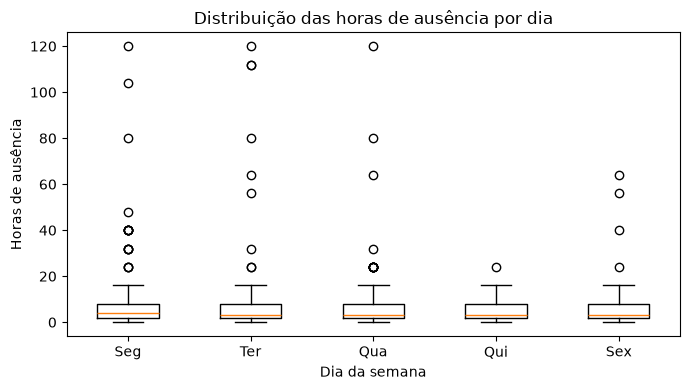

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot(
    [df.loc[df["dia"] == d, "horas"].values for d in ORDEM],
    tick_labels=ORDEM,
    showfliers=True,
)
ax.set_xlabel("Dia da semana")
ax.set_ylabel("Horas de ausência")
ax.set_title("Distribuição das horas de ausência por dia")
plt.tight_layout()
plt.show()

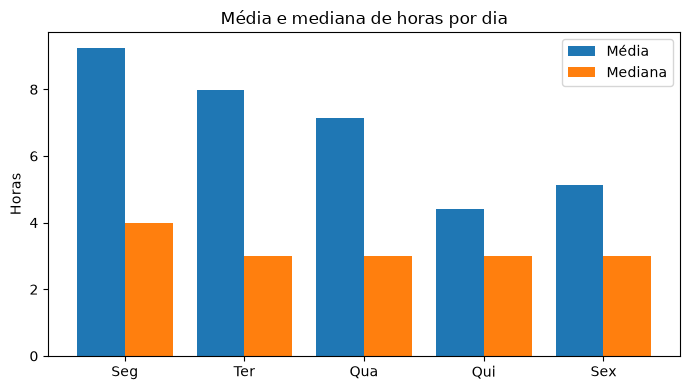

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(ORDEM))
ax.bar(x - 0.2, desc["media"], width=0.4, label="Média")
ax.bar(x + 0.2, desc["mediana"], width=0.4, label="Mediana")
ax.set_xticks(x)
ax.set_xticklabels(ORDEM)
ax.set_ylabel("Horas")
ax.set_title("Média e mediana de horas por dia")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Teste principal (H1) - Kruskal–Wallis

In [8]:
grupos = [df.loc[df["dia"] == d, "horas"].values for d in ORDEM]
H, p_kw = stats.kruskal(*grupos)
print(f"Kruskal-Wallis: H={H:.4f}, p={p_kw:.6g}")
print("rejeita H0 (alpha=0.05):", p_kw < 0.05)

Kruskal-Wallis: H=10.9554, p=0.0270694
rejeita H0 (alpha=0.05): True


## 6. Pós-teste - Mann–Whitney pares (Bonferroni)

In [9]:
pares = list(combinations(ORDEM, 2))
alpha = 0.05
rows = []
for a, b in pares:
    xa = df.loc[df["dia"] == a, "horas"]
    xb = df.loc[df["dia"] == b, "horas"]
    u, p = stats.mannwhitneyu(xa, xb, alternative="two-sided")
    rows.append({"par": f"{a} vs {b}", "U": u, "p": p, "p_bonf": min(p * len(pares), 1.0)})

post = pd.DataFrame(rows).sort_values("p")
post["sig_bonf"] = post["p_bonf"] < alpha
post

,par,U,p,p_bonf,sig_bonf
2,Seg vs Qui,12103.5000,0.0027,0.0271,True
3,Seg vs Sex,13502.0000,0.0112,0.1121,False
0,Seg vs Ter,14129.0000,0.0286,0.2859,False
1,Seg vs Qua,13827.0000,0.1124,1.0000,False
7,Qua vs Qui,10735.5000,0.1384,1.0000,False
8,Qua vs Sex,11832.5000,0.4149,1.0000,False
9,Qui vs Sex,8518.5000,0.4410,1.0000,False
5,Ter vs Qui,10114.5000,0.4576,1.0000,False
4,Ter vs Qua,11500.5000,0.5091,1.0000,False
6,Ter vs Sex,11197.5000,0.8811,1.0000,False


## 7. Teste dirigido (H2) - segunda vs demais dias

In [10]:
seg = df.loc[df["dia"] == "Seg", "horas"]
outros = df.loc[df["dia"] != "Seg", "horas"]
u_dir, p_dir = stats.mannwhitneyu(seg, outros, alternative="greater")
print(f"Seg n={len(seg)} mediana={seg.median():.2f} media={seg.mean():.2f}")
print(f"Outros n={len(outros)} mediana={outros.median():.2f} media={outros.mean():.2f}")
print(f"Mann-Whitney (Seg > Outros): U={u_dir:.1f}, p={p_dir:.6g}")

Seg n=161 mediana=4.00 media=9.25
Outros n=579 mediana=3.00 media=6.28
Mann-Whitney (Seg > Outros): U=53561.5, p=0.0015706


## 8. Sensibilidade (robustez de H1)

In [ ]:
# sem horas == 0
df1 = df[df["horas"] > 0]
g1 = [df1.loc[df1["dia"] == d, "horas"].values for d in ORDEM]
H1, p1 = stats.kruskal(*g1)
print(f"KW sem zeros (n={len(df1)}): H={H1:.4f}, p={p1:.6g}")

KW sem zeros (n=696): H=12.0310, p=0.0171223


In [ ]:
# sem outliers extremos (horas <= P95 global)
lim = df["horas"].quantile(0.95)
df2 = df[df["horas"] <= lim]
g2 = [df2.loc[df2["dia"] == d, "horas"].values for d in ORDEM]
H2, p2 = stats.kruskal(*g2)
print(f"KW horas<=P95={lim:.0f} (n={len(df2)}): H={H2:.4f}, p={p2:.6g}")

KW horas<=P95=24 (n=712): H=5.1685, p=0.270437


In [ ]:
# média de horas por funcionário e dia (atenua dependência intra-ID)
agg = df.groupby(["ID", "dia"], observed=True)["horas"].mean().reset_index()
g3 = [agg.loc[agg["dia"] == d, "horas"].values for d in ORDEM]
H3, p3 = stats.kruskal(*g3)
print(f"KW média por ID×dia (n={len(agg)}): H={H3:.4f}, p={p3:.6g}")
agg.groupby("dia", observed=True)["horas"].agg(["count", "mean", "median"]).reindex(ORDEM)

KW média por ID×dia (n=142): H=5.0837, p=0.27882


,count,mean,median
dia,,,
Seg,30,8.5691,6.9167
Ter,28,7.3704,5.3889
Qua,29,6.3890,4.2414
Qui,29,5.1555,4.0000
Sex,26,5.6670,4.9286


## 9. Síntese dos p-valores

In [14]:
sintese = pd.DataFrame([
    {"teste": "Kruskal-Wallis (completo)", "p": p_kw},
    {"teste": "Mann-Whitney Seg > Outros", "p": p_dir},
    {"teste": "KW sem zeros", "p": p1},
    {"teste": "KW sem outliers (>P95)", "p": p2},
    {"teste": "KW média ID×dia", "p": p3},
])
sintese["p<0.05"] = sintese["p"] < 0.05
sintese

,teste,p,p<0.05
0,Kruskal-Wallis (completo),0.0271,True
1,Mann-Whitney Seg > Outros,0.0016,True
2,KW sem zeros,0.0171,True
3,KW sem outliers (>P95),0.2704,False
4,KW média ID×dia,0.2788,False


## 10. Extras - tamanho de efeito e ausências longas (apoio a H2)

In [15]:
# epsilon-squared do Kruskal-Wallis (efeito global)
n = len(df)
eps2 = H / (n - 1)
print(f"epsilon^2 (KW completo) = {eps2:.4f}")
print("referencia informal: ~0.01 pequeno, ~0.06 medio, ~0.14 grande")

def cliff_delta(x, y):
    x = np.asarray(x)
    y = np.asarray(y)
    more = sum((xi > y).sum() for xi in x)
    less = sum((xi < y).sum() for xi in x)
    return (more - less) / (len(x) * len(y))

d = cliff_delta(seg.values, outros.values)
print(f"Cliff delta (Seg vs Outros) = {d:.4f}  (positivo => Seg tende a valores maiores)")


epsilon^2 (KW completo) = 0.0148
referencia informal: ~0.01 pequeno, ~0.06 medio, ~0.14 grande
Cliff delta (Seg vs Outros) = 0.1492  (positivo => Seg tende a valores maiores)


In [16]:
# ausencia longa: horas >= 8
df["longa"] = (df["horas"] >= 8).astype(int)
tab = pd.crosstab(df["dia"], df["longa"]).reindex(ORDEM)
tab.columns = ["curta(<8h)", "longa(>=8h)"]
tab["pct_longa"] = tab["longa(>=8h)"] / (tab["curta(<8h)"] + tab["longa(>=8h)"])
print(tab)
chi2, p_chi, dof, _ = stats.chi2_contingency(tab[["curta(<8h)", "longa(>=8h)"]])
print(f"Qui-quadrado: chi2={chi2:.4f}, dof={dof}, p={p_chi:.6g}")


     curta(<8h)  longa(>=8h)  pct_longa
dia                                    
Seg          86           75     0.4658
Ter          96           58     0.3766
Qua          96           60     0.3846
Qui          89           36     0.2880
Sex         102           42     0.2917
Qui-quadrado: chi2=13.9265, dof=4, p=0.00753329
